In [1]:
import duckdb

con = duckdb.connect()
con.execute("""
    INSTALL httpfs; LOAD httpfs;
    SET s3_endpoint='localhost:9000';
    SET s3_access_key_id='minioadmin';
    SET s3_secret_access_key='minioadmin';
    SET s3_use_ssl=false;
    SET s3_url_style='path';
""")

df = con.execute("""
    SELECT * FROM read_parquet('s3://company-raw-data/processed_zone/preprocessed_sales_data.parquet')
""").df()

df.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,date,store_id,product_id,category,quantity_sold,unit_price_egp,discount_percent,inventory_level,reorder_point,days_of_supply,...,is_month_start,is_month_end,quantity_lag_1,quantity_lag_7,quantity_lag_14,quantity_lag_28,quantity_roll_mean_7,quantity_roll_mean_28,quantity_roll_std_7,quantity_roll_std_28
0,2023-01-01,0.0,0.0,0.0,0,450,0.0,36.0,20.0,18.0,...,True,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2023-01-02,0.0,0.0,0.0,1,450,0.0,36.0,20.0,18.0,...,False,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2023-01-03,0.0,0.0,0.0,1,450,0.0,36.0,20.0,18.0,...,False,False,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2023-01-04,0.0,0.0,0.0,1,450,0.0,36.0,20.0,18.0,...,False,False,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2023-01-05,0.0,0.0,0.0,1,450,0.0,36.0,20.0,18.0,...,False,False,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df.shape

(47489, 31)

<Axes: >

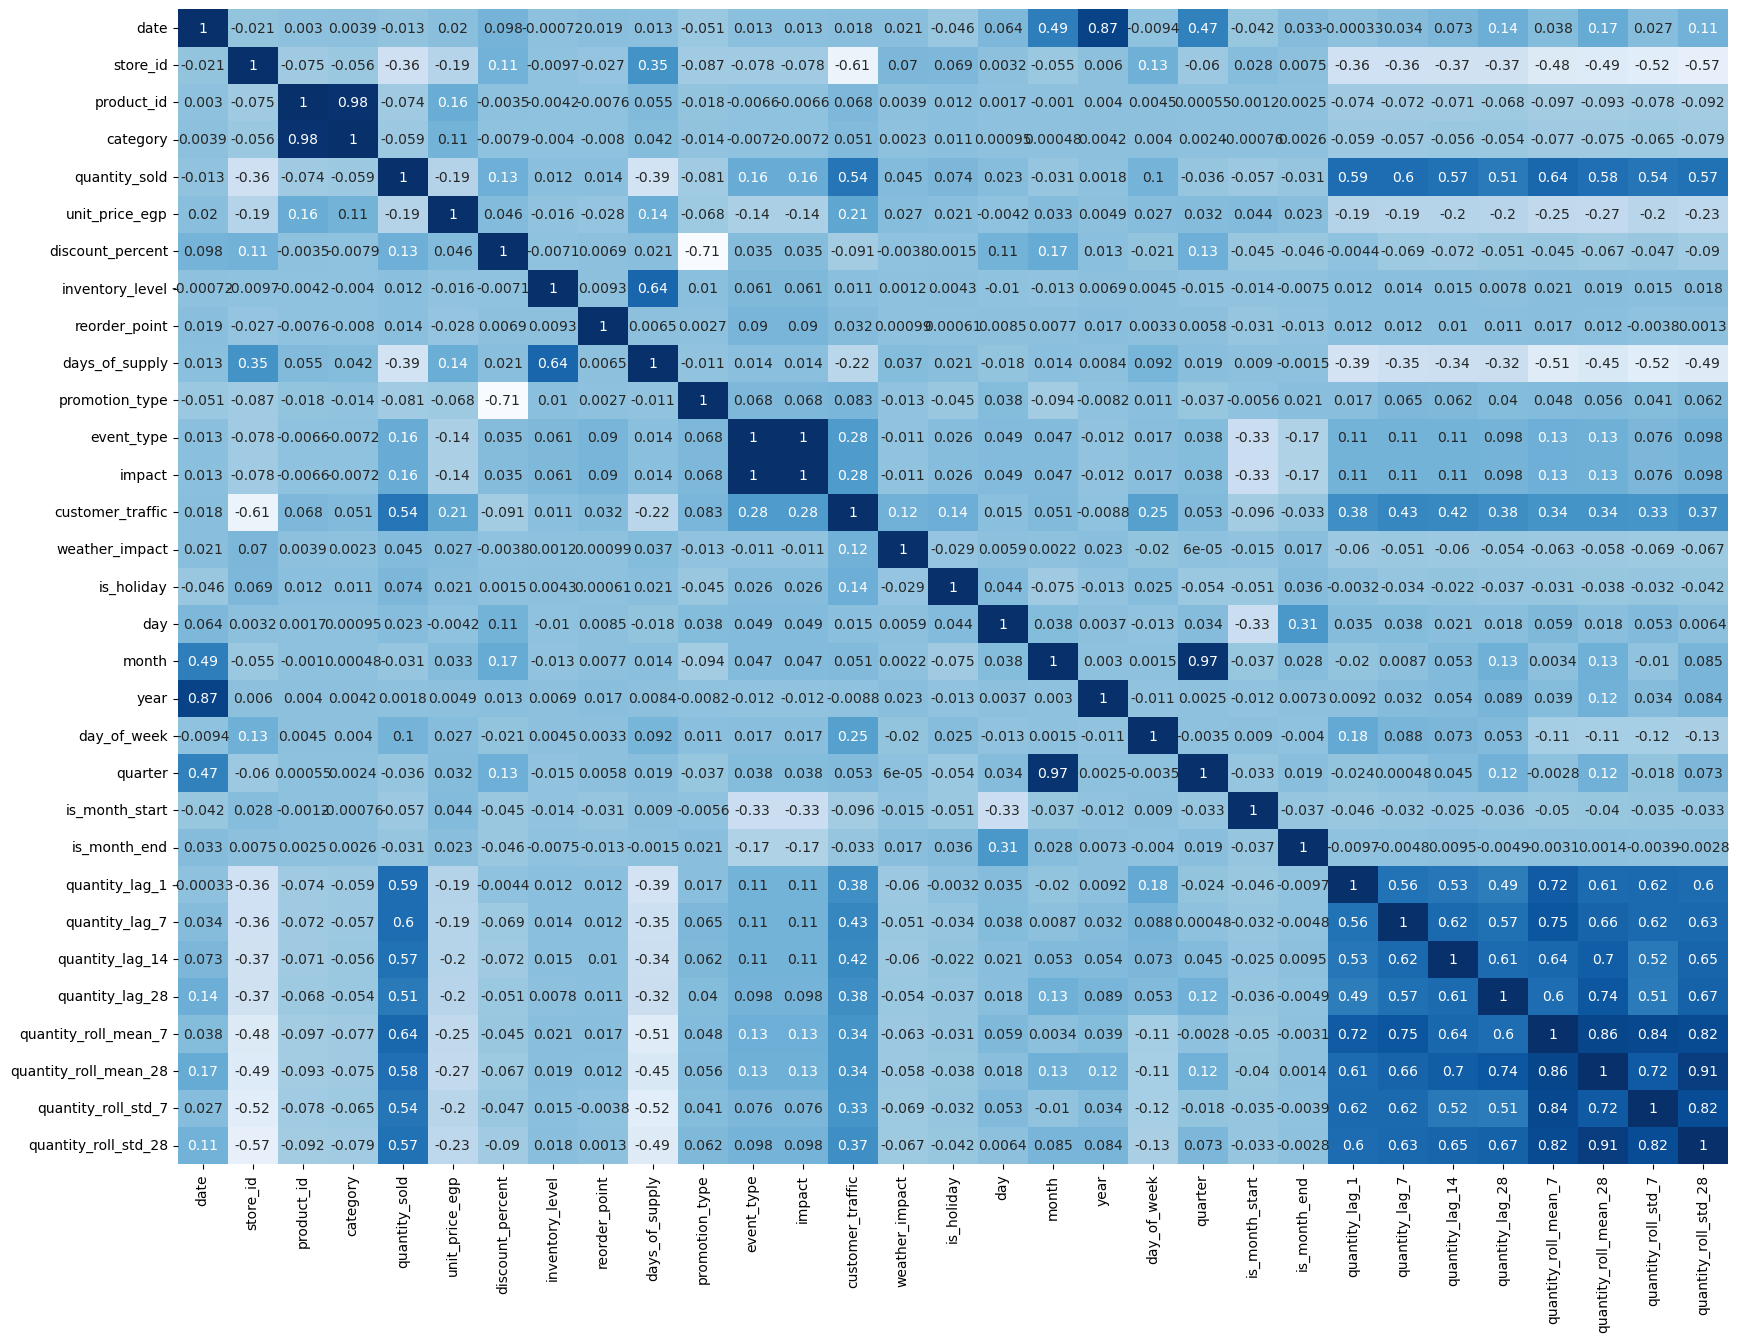

In [8]:
plt.figure(figsize=(20, 15))
sns.heatmap(df.corr(), cbar=False, annot=True, cmap='Blues')